In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. 设置中文字体为黑体
plt.rcParams['font.sans-serif'] = ['SimHei'] 
# 2. 正常显示负号（防止坐标轴上的负数变成方块）
plt.rcParams['axes.unicode_minus'] = False 

# 然后就直接画你的图就行了
con = duckdb.connect("data/criteo_analysis.duckdb")

## 5. 触点价值：成本与归因信用是否错配

活动层分析回答“预算给了哪些活动”，触点层分析回答“活动内部的预算是否给错了点击位置”。

本节比较四种归因规则：

1. Last-click：真实末次点击获得全部信用。
2. Linear：路径内每个点击平分信用。
3. Position 40/20/40：首次和末次各 40%，中间点击合计 20%。
4. Time-decay：距离转化越近的点击权重越高，使用 7 天半衰期。

位置归因只使用完整路径。相对出价系数定义为：

`出价系数 = 三模型平均信用占比 / 成本占比`

这里的系数只表示完整路径内部的相对再分配信号，不是真实出价倍数。

In [2]:
#生成四种归因信用
con.execute("""
CREATE OR REPLACE TABLE attribution_credit AS
WITH weighted AS (
    SELECT
        *,
        count(*) OVER event_window AS cnt,
        pow(2, -conv_delay_sec / (86400.0 * 7)) AS decay_raw
    FROM conversion_path
    WHERE is_path_complete
    WINDOW event_window AS (
        PARTITION BY uid, conversion_id
    )
),
credited AS (
    SELECT
        *,
        is_last_click::INT AS w_last,
        1.0 / cnt AS w_linear,

        CASE
            WHEN cnt = 1 THEN 1.0
            WHEN cnt = 2 THEN 0.5
            WHEN is_first_click THEN 0.4
            WHEN is_last_click THEN 0.4
            ELSE 0.2 / (cnt - 2)
        END AS w_pos,

        decay_raw
        / sum(decay_raw) OVER (
            PARTITION BY uid, conversion_id
        ) AS w_time,

        CASE
            WHEN cnt = 1 THEN '单点击'
            WHEN is_first_click THEN '首次'
            WHEN is_last_click THEN '末次'
            ELSE '中间'
        END AS position
    FROM weighted
)
SELECT
    uid,
    conversion_id,
    campaign,
    path_pos,
    cnt,
    position,
    cost,
    conv_delay_days,
    is_attributed AS official_attr,
    w_last,
    w_linear,
    w_pos,
    w_time
FROM credited
""")

con.sql("""
SELECT *
FROM attribution_credit
ORDER BY cost DESC
LIMIT 5
""").df()

,uid,conversion_id,campaign,path_pos,cnt,position,cost,conv_delay_days,official_attr,w_last,w_linear,w_pos,w_time
0,9634988,16253083,28351001,0,12,首次,0.057502,4.585312,True,0,0.083333,0.400000,0.067479
1,5543542,2205467,12987593,38,54,中间,0.056817,4.797674,True,0,0.018519,0.003846,0.027583
2,5543542,2205467,12987593,35,54,中间,0.056663,5.469051,True,0,0.018519,0.003846,0.025809
3,5543542,2205467,12987593,43,54,中间,0.056620,4.135231,True,0,0.018519,0.003846,0.029453
4,5543542,2205467,12987593,45,54,中间,0.056280,3.745787,True,0,0.018519,0.003846,0.030611


In [3]:
#检查模型信用是否守恒
con.execute("""
CREATE OR REPLACE TABLE attribution_model_check AS
WITH event_credit AS (
    SELECT
        uid,
        conversion_id,
        sum(w_last) AS last_credit,
        sum(w_linear) AS linear_credit,
        sum(w_pos) AS position_credit,
        sum(w_time) AS time_credit
    FROM attribution_credit
    GROUP BY uid, conversion_id
)
SELECT
    count(*) AS events,
    round(min(last_credit), 6) AS last_min,
    round(max(last_credit), 6) AS last_max,
    round(min(linear_credit), 6) AS linear_min,
    round(max(linear_credit), 6) AS linear_max,
    round(min(position_credit), 6) AS position_min,
    round(max(position_credit), 6) AS position_max,
    round(min(time_credit), 6) AS time_min,
    round(max(time_credit), 6) AS time_max
FROM event_credit
""")

con.sql("""
SELECT *
FROM attribution_model_check
""").df()

,events,last_min,last_max,linear_min,linear_max,position_min,position_max,time_min,time_max
0,362504,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [4]:
#计算位置成本与信用
con.execute("""
CREATE OR REPLACE TABLE position_credit AS
SELECT
    position,
    count(*) AS path_rows,
    round(avg(cost), 6) AS avg_cost,
    round(sum(cost), 2) AS cost,

    round(
        100.0 * sum(cost)
        / sum(sum(cost)) OVER (),
        2
    ) AS cost_pct,

    round(
        100.0 * sum(w_last)
        / sum(sum(w_last)) OVER (),
        2
    ) AS last_pct,

    round(
        100.0 * sum(w_linear)
        / sum(sum(w_linear)) OVER (),
        2
    ) AS linear_pct,

    round(
        100.0 * sum(w_pos)
        / sum(sum(w_pos)) OVER (),
        2
    ) AS position_pct,

    round(
        100.0 * sum(w_time)
        / sum(sum(w_time)) OVER (),
        2
    ) AS time_pct,

    round(
        100.0
        * (sum(w_linear) + sum(w_pos) + sum(w_time))
        / (
            3.0
            * (SELECT sum(w_linear) FROM attribution_credit)
        ),
        2
    ) AS credit_pct
FROM attribution_credit
GROUP BY position
""")

con.sql("""
SELECT *
FROM position_credit
ORDER BY path_rows DESC
""").df()

,position,path_rows,avg_cost,cost,cost_pct,last_pct,linear_pct,position_pct,time_pct,credit_pct
0,单点击,260774,0.000558,145.47,25.07,71.94,71.94,71.94,71.94,71.94
1,中间,135911,0.001601,217.62,37.50,0.00,6.35,2.56,6.13,5.01
2,末次,101730,0.001354,137.78,23.74,28.06,10.86,12.75,13.16,12.26
3,首次,101730,0.000781,79.41,13.68,0.00,10.86,12.75,8.77,10.79


In [5]:
#生成相对出价系数
con.execute("""
CREATE OR REPLACE TABLE position_bid_multipliers AS
SELECT
    position,
    path_rows,
    avg_cost,
    cost_pct,
    credit_pct,
    round(credit_pct / cost_pct, 3) AS bid_multiplier,

    CASE
        WHEN credit_pct / cost_pct > 1.15 THEN '加价'
        WHEN credit_pct / cost_pct < 0.85 THEN '降价'
        ELSE '维持'
    END AS action
FROM position_credit
""")

display(con.sql("""
SELECT *
FROM position_bid_multipliers
ORDER BY bid_multiplier DESC
""").df())

display(con.sql("""
SELECT
    round(
        sum(cost_pct * bid_multiplier),
        2
    ) AS weighted_multiplier_check
FROM position_bid_multipliers
""").df())

,position,path_rows,avg_cost,cost_pct,credit_pct,bid_multiplier,action
0,单点击,260774,0.000558,25.07,71.94,2.870,加价
1,首次,101730,0.000781,13.68,10.79,0.789,降价
2,末次,101730,0.001354,23.74,12.26,0.516,降价
3,中间,135911,0.001601,37.50,5.01,0.134,降价


,weighted_multiplier_check
0,100.02


In [6]:
#检查出价建议的适用范围
con.execute("""
CREATE OR REPLACE TABLE bid_scope AS
SELECT
    round(
        (SELECT sum(cost) FROM attribution_credit),
        2
    ) AS complete_path_cost,

    round(
        (SELECT sum(cost) FROM campaign_stats),
        2
    ) AS total_site_cost,

    round(
        100.0
        * (SELECT sum(cost) FROM attribution_credit)
        / (SELECT sum(cost) FROM campaign_stats),
        1
    ) AS complete_path_cost_pct
""")

con.sql("""
SELECT *
FROM bid_scope
""").df()

,complete_path_cost,total_site_cost,complete_path_cost_pct
0,580.27,4829.34,12.0


位置结果的核心不是“中间点击应该打几折”，而是成本与信用出现了明显错配：

- 中间点击占完整路径成本 37.50%，三模型平均信用只有 5.01%。
- 相对出价系数只有 0.134，是四个位置中最低。
- 单点击路径系数为 2.870，但这是高意向路径结构导致的结果，不能解释为单次曝光具有三倍因果价值。
- 首次点击系数为 0.789，接近中性。
- 末次点击系数为 0.516，不应继续按当前成本获得同等预算。

完整路径成本只占全站成本约 12%，因此这些系数不能直接外推到全部预算。

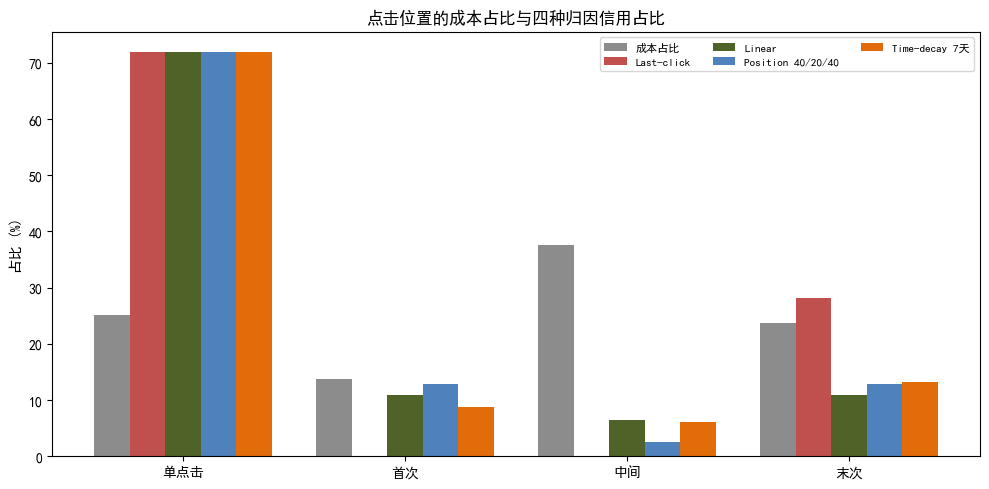

In [7]:
#绘制成本与四种归因信用
positions = ["单点击", "首次", "中间", "末次"]

position = (
    con.sql("""
        SELECT *
        FROM position_credit
    """)
    .df()
    .set_index("position")
    .reindex(positions)
)

x = range(len(positions))
width = 0.16

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    [i - 2 * width for i in x],
    position["cost_pct"],
    width,
    label="成本占比",
    color="#8C8C8C"
)
ax.bar(
    [i - width for i in x],
    position["last_pct"],
    width,
    label="Last-click",
    color="#C0504D"
)
ax.bar(
    x,
    position["linear_pct"],
    width,
    label="Linear",
    color="#4F6228"
)
ax.bar(
    [i + width for i in x],
    position["position_pct"],
    width,
    label="Position 40/20/40",
    color="#4F81BD"
)
ax.bar(
    [i + 2 * width for i in x],
    position["time_pct"],
    width,
    label="Time-decay 7天",
    color="#E36C0A"
)

ax.set_xticks(list(x))
ax.set_xticklabels(positions)
ax.set_ylabel("占比 (%)")
ax.set_title("点击位置的成本占比与四种归因信用占比")
ax.legend(fontsize=8, ncol=3)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "05_position_credit.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 6. 结论是否稳健

前面的位置和活动结论都来自历史样本。还需要检查三个问题：

1. 全表 36.12% 的点击率明显偏高，绝对 CPA 是否可靠？
2. 高频曝光是否真的带来了更高转化，还是高意向用户本来就会被重复触达？
3. 不同归因窗口是否会改变成本覆盖和 CPA 判断？

本节不引入新的业务结论，只检验前面的结论在什么条件下仍然成立。

6.1 IPW 稳健性
活动级 IPW 基础表

In [8]:
con.execute("""
CREATE OR REPLACE TABLE campaign_ipw_base AS
WITH campaign_spend AS (
    SELECT
        campaign,
        sum(click) AS a1,
        count(*) - sum(click) AS a0,
        sum(cost) FILTER (
            WHERE click = 1
        ) AS k1,
        sum(cost) FILTER (
            WHERE click = 0
        ) AS k0
    FROM raw
    GROUP BY campaign
),
campaign_attr AS (
    SELECT
        campaign,
        count(DISTINCT (uid, conversion_id)) FILTER (
            WHERE conversion = 1
            AND attribution = 1
        ) AS attributed_events
    FROM raw
    GROUP BY campaign
)
SELECT
    s.campaign,
    s.a1,
    s.a0,
    s.k1,
    s.k0,
    coalesce(a.attributed_events, 0) AS attributed_events
FROM campaign_spend AS s
LEFT JOIN campaign_attr AS a
    USING (campaign)
""")

con.sql("""
SELECT *
FROM campaign_ipw_base
ORDER BY campaign
LIMIT 5
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,campaign,a1,a0,k1,k0,attributed_events
0,73322,222.0,513.0,0.073549,0.041494,46
1,73325,1511.0,4181.0,0.231116,0.194179,210
2,73327,1699.0,5696.0,0.776072,0.677987,566
3,73328,4218.0,8732.0,0.598896,0.402242,651
4,83677,12682.0,29996.0,7.173679,5.903389,103


生成 IPW 情景表

In [9]:
con.execute("""
CREATE OR REPLACE TABLE ipw_scenarios AS
WITH totals AS (
    SELECT
        sum(a1) AS n1,
        sum(a0) AS n0,
        sum(k1) AS c1,
        sum(k0) AS c0,
        sum(attributed_events) AS attributed_events
    FROM campaign_ipw_base
),
scenarios AS (
    SELECT assumed_ctr
    FROM (
        VALUES
            (0.001),
            (0.002),
            (0.005),
            (0.01),
            (0.05),
            (0.3612)
    ) AS t(assumed_ctr)
)
SELECT
    assumed_ctr,
    round((n1 / n0) * ((1 - assumed_ctr) / assumed_ctr),2) AS w_nonclick,
    round(n1 / (n1 + (n1 / n0) * ((1 - assumed_ctr) / assumed_ctr) * n0),6) AS weighted_ctr,
    round((c1 + (n1 / n0) * ((1 - assumed_ctr) / assumed_ctr) * c0) / (c1 + c0),2) AS cost_multiplier,
    round((c1 + (n1 / n0) * ((1 - assumed_ctr) / assumed_ctr) * c0) / attributed_events,4) AS weighted_cpa
FROM totals
CROSS JOIN scenarios
ORDER BY assumed_ctr
""")

con.sql("""
SELECT *
FROM ipw_scenarios
""").df()

,assumed_ctr,w_nonclick,weighted_ctr,cost_multiplier,weighted_cpa
0,0.0010,564.77,0.0010,211.58,4.3085
1,0.0020,282.10,0.0020,106.00,2.1585
2,0.0050,112.50,0.0050,42.65,0.8685
3,0.0100,55.97,0.0100,21.53,0.4385
4,0.0500,10.74,0.0500,4.64,0.0945
5,0.3612,1.00,0.3612,1.00,0.0204


检查活动排名稳定性

In [10]:
from scipy.stats import spearmanr

campaign_ipw = con.sql("""
SELECT
    *,
    a1 / (a1 + a0) AS ctr,
    (k1 + k0) / NULLIF(attributed_events, 0) AS cpa
FROM campaign_ipw_base
WHERE attributed_events > 0
""").df()

n1 = campaign_ipw["a1"].sum()
n0 = campaign_ipw["a0"].sum()

rank_rows = []

for assumed_ctr in (0.002, 0.01, 0.05):
    w_nonclick = (n1 / n0) * (
        (1 - assumed_ctr) / assumed_ctr
    )

    current = campaign_ipw.copy()
    current["ctr"] = current["a1"] / (
        current["a1"] + w_nonclick * current["a0"]
    )
    current["cpa"] = (
        current["k1"] + w_nonclick * current["k0"]
    ) / current["attributed_events"]

    ctr_correlation = spearmanr(
        campaign_ipw["ctr"],
        current["ctr"]
    ).statistic

    cpa_correlation = spearmanr(
        campaign_ipw["cpa"],
        current["cpa"]
    ).statistic

    rank_rows.append({
        "assumed_ctr": assumed_ctr,
        "nonclick_weight": w_nonclick,
        "ctr_rank_corr": ctr_correlation,
        "cpa_rank_corr": cpa_correlation
    })

ipw_rank_stability = pd.DataFrame(rank_rows)

con.register("ipw_rank_stability_df", ipw_rank_stability)
con.execute("""
CREATE OR REPLACE TABLE ipw_rank_stability AS
SELECT *
FROM ipw_rank_stability_df
""")
con.unregister("ipw_rank_stability_df")

ipw_rank_stability

,assumed_ctr,nonclick_weight,ctr_rank_corr,cpa_rank_corr
0,0.002,282.101050,1.0,0.968726
1,0.010,55.967944,1.0,0.970942
2,0.050,10.741323,1.0,0.980176


In [11]:
#中间点击重新加权敏感性
con.execute("""
CREATE OR REPLACE TABLE position_reweight_sensitivity AS
WITH base AS (
    SELECT
        sum(cost) AS total_cost,
        sum(
            (w_linear + w_pos + w_time) / 3.0
        ) AS total_credit,
        sum(cost) FILTER (
            WHERE position = '中间'
        ) AS mid_cost,
        sum(
            (w_linear + w_pos + w_time) / 3.0
        ) FILTER (
            WHERE position = '中间'
        ) AS mid_credit
    FROM attribution_credit
),
weight_values AS (
    SELECT k
    FROM (
        VALUES
            (0.25),
            (0.5),
            (1.0),
            (2.0),
            (5.0),
            (10.0),
            (12.0),
            (20.0),
            (50.0)
    ) AS t(k)
),
scaled AS (
    SELECT
        k,
        (mid_cost * k)
        / (total_cost - mid_cost + mid_cost * k)
            AS cost_share,
        (mid_credit * k)
        / (total_credit - mid_credit + mid_credit * k)
            AS credit_share
    FROM base
    CROSS JOIN weight_values
)
SELECT
    k,
    round(100.0 * cost_share, 2) AS mid_cost_pct,
    round(100.0 * credit_share, 2) AS mid_credit_pct,
    round(credit_share / cost_share, 3) AS credit_cost_ratio
FROM scaled
ORDER BY k
""")

con.sql("""
SELECT *
FROM position_reweight_sensitivity
ORDER BY k
""").df()

,k,mid_cost_pct,mid_credit_pct,credit_cost_ratio
0,0.25,13.04,1.30,0.100
1,0.50,23.08,2.57,0.111
2,1.00,37.50,5.01,0.134
3,2.00,54.55,9.55,0.175
4,5.00,75.00,20.88,0.278
5,10.00,85.72,34.55,0.403
6,12.00,87.81,38.78,0.442
7,20.00,92.31,51.36,0.556
8,50.00,96.77,72.52,0.749


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


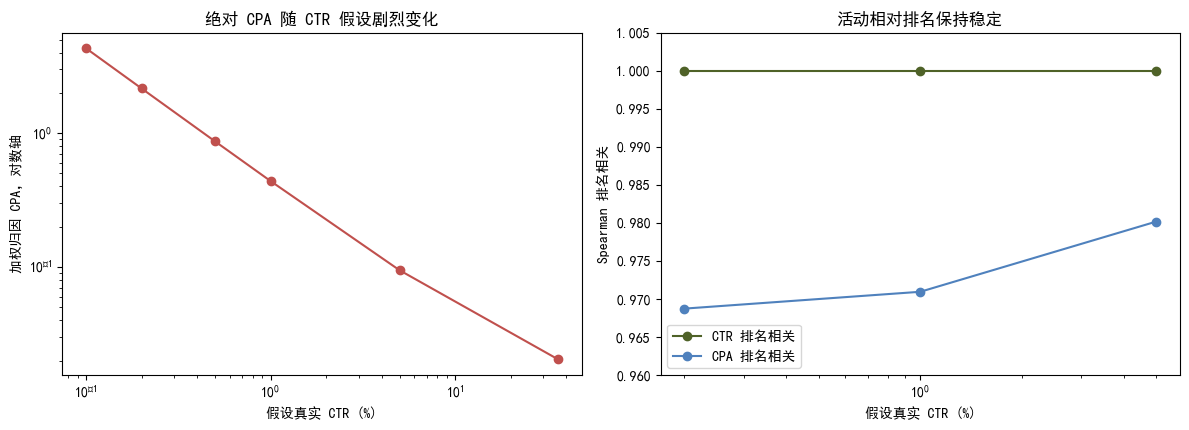

In [12]:
#IPW 稳健性图
ipw = con.sql("""
SELECT *
FROM ipw_scenarios
ORDER BY assumed_ctr
""").df()

ranks = con.sql("""
SELECT *
FROM ipw_rank_stability
ORDER BY assumed_ctr
""").df()

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(12, 4.4)
)

ax1.plot(
    ipw["assumed_ctr"] * 100,
    ipw["weighted_cpa"],
    marker="o",
    color="#C0504D"
)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("假设真实 CTR (%)")
ax1.set_ylabel("加权归因 CPA，对数轴")
ax1.set_title("绝对 CPA 随 CTR 假设剧烈变化")

ax2.plot(
    ranks["assumed_ctr"] * 100,
    ranks["ctr_rank_corr"],
    marker="o",
    label="CTR 排名相关",
    color="#4F6228"
)
ax2.plot(
    ranks["assumed_ctr"] * 100,
    ranks["cpa_rank_corr"],
    marker="o",
    label="CPA 排名相关",
    color="#4F81BD"
)
ax2.set_xscale("log")
ax2.set_ylim(0.96, 1.005)
ax2.set_xlabel("假设真实 CTR (%)")
ax2.set_ylabel("Spearman 排名相关")
ax2.set_title("活动相对排名保持稳定")
ax2.legend()

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "06_ipw_robustness.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

IPW 结果说明：

- 绝对 CPA 会随着 CTR 假设变化约 211 倍，不能对外部行业或真实业务做绝对金额对标。
- 活动 CTR 和 CPA 的相对排名基本稳定，因此可以继续使用组内相对比较。
- 中间点击的成本与信用同时放缩后，信用/成本比只会趋近 1，没有有限翻转点。
- 旧结论中的“过采样 12 倍翻转”不再成立，因为它只放缩了成本，没有同步放缩信用。

6.2 曝光频次
建立频次分桶

In [13]:
con.execute("""
CREATE OR REPLACE TABLE frequency_buckets AS
WITH user_impression AS (
    SELECT
        uid,
        count(*) AS impressions,
        sum(cost) AS cost
    FROM raw
    GROUP BY uid
),
user_event AS (
    SELECT
        uid,
        count(*) AS event_count
    FROM conversion_events
    GROUP BY uid
),
user_bucket AS (
    SELECT
        u.uid,
        u.impressions,
        u.cost,
        coalesce(e.event_count, 0) AS event_count,

        CASE
            WHEN u.impressions = 1 THEN '1'
            WHEN u.impressions = 2 THEN '2'
            WHEN u.impressions = 3 THEN '3'
            WHEN u.impressions = 4 THEN '4'
            WHEN u.impressions <= 7 THEN '5-7'
            WHEN u.impressions <= 15 THEN '8-15'
            WHEN u.impressions <= 30 THEN '16-30'
            WHEN u.impressions <= 100 THEN '31-100'
            ELSE '100+'
        END AS bucket,

        CASE
            WHEN u.impressions = 1 THEN 1
            WHEN u.impressions = 2 THEN 2
            WHEN u.impressions = 3 THEN 3
            WHEN u.impressions = 4 THEN 4
            WHEN u.impressions <= 7 THEN 5
            WHEN u.impressions <= 15 THEN 6
            WHEN u.impressions <= 30 THEN 7
            WHEN u.impressions <= 100 THEN 8
            ELSE 9
        END AS bucket_order
    FROM user_impression AS u
    LEFT JOIN user_event AS e
        USING (uid)
)
SELECT
    bucket,
    bucket_order,
    count(*) AS users,
    round(
        100.0 * count(*) / sum(count(*)) OVER (),
        1
    ) AS users_pct,
    sum(impressions) AS impressions,
    round(
        100.0 * sum(impressions)
        / sum(sum(impressions)) OVER (),
        1
    ) AS impression_pct,
    round(sum(cost), 1) AS cost,
    round(
        100.0 * sum(cost) / sum(sum(cost)) OVER (),
        1
    ) AS cost_pct,
    sum(event_count) AS event_count,
    round(
        100.0 * count(*) FILTER (
            WHERE event_count > 0
        ) / count(*),
        2
    ) AS user_conv_rate_pct,
    round(
        1000.0 * sum(event_count) / sum(impressions),
        2
    ) AS events_per_1k_imp,
    round(
        sum(cost) / NULLIF(sum(event_count), 0),
        4
    ) AS cost_per_event
FROM user_bucket
GROUP BY bucket, bucket_order
ORDER BY bucket_order
""")

con.sql("""
SELECT *
FROM frequency_buckets
ORDER BY bucket_order
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,bucket,bucket_order,users,users_pct,impressions,impression_pct,cost,cost_pct,event_count,user_conv_rate_pct,events_per_1k_imp,cost_per_event
0,1,1,3175158,51.7,3175158.0,19.3,411.0,8.5,52091.0,1.64,16.41,0.0079
1,2,2,1190099,19.4,2380198.0,14.5,413.9,8.6,50913.0,4.03,21.39,0.0081
2,3,3,591322,9.6,1773966.0,10.8,375.3,7.8,44162.0,6.62,24.89,0.0085
3,4,4,342342,5.6,1369368.0,8.3,333.6,6.9,37106.0,9.13,27.10,0.0090
4,5-7,5,466765,7.6,2686534.0,16.3,780.9,16.2,80280.0,13.30,29.88,0.0097
5,8-15,6,290235,4.7,2989565.0,18.2,1150.9,23.8,97691.0,21.79,32.68,0.0118
6,16-30,7,72409,1.2,1473818.0,8.9,807.8,16.7,53306.0,34.92,36.17,0.0152
7,31-100,8,13648,0.2,577886.0,3.5,508.3,10.5,22190.0,49.11,38.40,0.0229
8,100+,9,278,0.0,41534.0,0.3,47.7,1.0,991.0,44.60,23.86,0.0481


频次与效率图

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

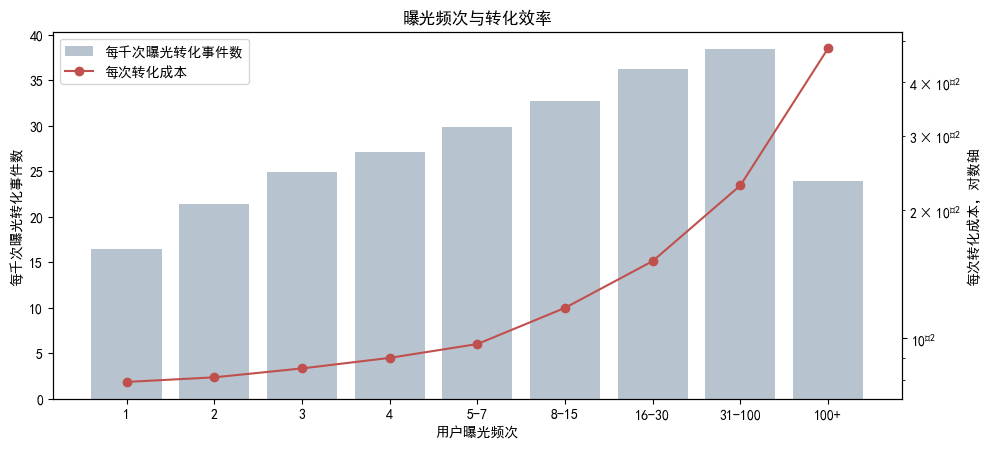

In [14]:
frequency = con.sql("""
SELECT *
FROM frequency_buckets
ORDER BY bucket_order
""").df()

fig, ax1 = plt.subplots(figsize=(10, 4.6))

ax1.bar(
    frequency["bucket"],
    frequency["events_per_1k_imp"],
    color="#B7C4CF",
    label="每千次曝光转化事件数"
)
ax1.set_xlabel("用户曝光频次")
ax1.set_ylabel("每千次曝光转化事件数")

ax2 = ax1.twinx()
ax2.plot(
    frequency["bucket"],
    frequency["cost_per_event"],
    marker="o",
    color="#C0504D",
    label="每次转化成本"
)
ax2.set_yscale("log")
ax2.set_ylabel("每次转化成本，对数轴")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

ax1.set_title("曝光频次与转化效率")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "07_frequency.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

每千次曝光转化事件数在 16～30 次曝光后基本走平，但单次转化成本继续上升，说明高频曝光的边际效率在下降。

同时，频次与转化是内生关系。高意向用户本来就可能被重复触达，因此不能把这组曲线解释成“增加曝光会直接提高转化率”。

100+ 频次用户只有 278 人，不应用来单独支撑强结论。

6.3 归因窗口与官方规则
建立窗口事件表和窗口汇总

In [15]:
con.execute("""
CREATE OR REPLACE TABLE conversion_event_window AS
SELECT
    uid,
    conversion_id,
    min(conv_delay_sec) AS last_delay,
    sum(cost) AS path_cost,
    coalesce(
        sum(cost) FILTER (
            WHERE conv_delay_sec <= 3600
        ),
        0
    ) AS cost_1h,
    coalesce(
        sum(cost) FILTER (
            WHERE conv_delay_sec <= 86400
        ),
        0
    ) AS cost_1d,
    coalesce(
        sum(cost) FILTER (
            WHERE conv_delay_sec <= 604800
        ),
        0
    ) AS cost_7d,
    max(is_attributed::INT) AS attributed
FROM conversion_path
WHERE is_path_complete
GROUP BY uid, conversion_id
""")

con.execute("""
CREATE OR REPLACE TABLE attribution_window AS
WITH windows AS (
    SELECT *
    FROM (
        VALUES
            ('1小时', 1, 3600),
            ('1天', 2, 86400),
            ('7天', 3, 604800),
            ('30天', 4, 2592000)
    ) AS t(window_label, window_order, window_seconds)
),
summary AS (
    SELECT
        w.window_label,
        w.window_order,
        count(*) FILTER (
            WHERE e.last_delay <= w.window_seconds
        ) AS event_count,
        sum(
            CASE w.window_order
                WHEN 1 THEN e.cost_1h
                WHEN 2 THEN e.cost_1d
                WHEN 3 THEN e.cost_7d
                ELSE e.path_cost
            END
        ) AS total_cost
    FROM conversion_event_window AS e
    CROSS JOIN windows AS w
    GROUP BY w.window_label, w.window_order
)
SELECT
    window_label,
    window_order,
    event_count,
    round(
        100.0 * event_count
        / (SELECT count(*) FROM conversion_event_window),
        1
    ) AS event_coverage_pct,
    round(total_cost, 2) AS cost,
    round(
        100.0 * total_cost
        / (
            SELECT sum(path_cost)
            FROM conversion_event_window
        ),
        1
    ) AS cost_coverage_pct,
    round(total_cost / event_count, 5) AS cpa,
    round(
        (
            total_cost
            - lag(total_cost) OVER (
                ORDER BY window_order
            )
        )
        / (
            event_count
            - lag(event_count) OVER (
                ORDER BY window_order
            )
        ),
        5
    ) AS marginal_cpa
FROM summary
ORDER BY window_order
""")

con.sql("""
SELECT *
FROM attribution_window
ORDER BY window_order
""").df()

,window_label,window_order,event_count,event_coverage_pct,cost,cost_coverage_pct,cpa,marginal_cpa
0,1小时,1,156006,43.0,148.33,25.6,0.00095,NaN
1,1天,2,205878,56.8,241.21,41.6,0.00117,0.00186
2,7天,3,286593,79.1,436.36,75.2,0.00152,0.00242
3,30天,4,362504,100.0,580.27,100.0,0.00160,0.00190


建立官方归因规则表

In [16]:
con.execute("""
CREATE OR REPLACE TABLE official_window_rule AS
SELECT
    CASE
        WHEN last_delay < 60 THEN 'a <1分钟'
        WHEN last_delay < 3600 THEN 'b 1分~1时'
        WHEN last_delay < 86400 THEN 'c 1时~1天'
        WHEN last_delay < 604800 THEN 'd 1~7天'
        ELSE 'e 7~30天'
    END AS delay_bucket,
    count(*) AS event_count,
    round(
        100.0 * sum(attributed) / count(*),
        1
    ) AS attribution_rate_pct
FROM conversion_event_window
GROUP BY delay_bucket
ORDER BY delay_bucket
""")

con.sql("""
SELECT *
FROM official_window_rule
ORDER BY delay_bucket
""").df()

,delay_bucket,event_count,attribution_rate_pct
0,a <1分钟,31569,88.6
1,b 1分~1时,124433,86.4
2,c 1时~1天,49875,47.3
3,d 1~7天,80716,31.0
4,e 7~30天,75911,14.8


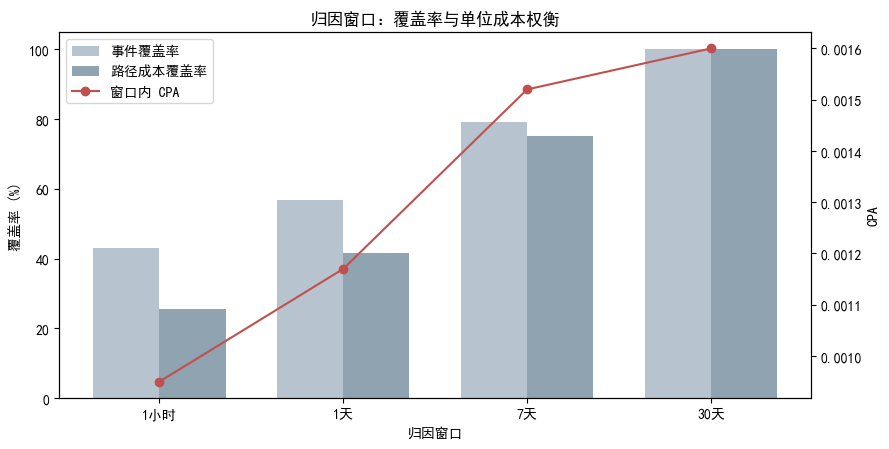

In [17]:
#窗口覆盖与 CPA 权衡图
window = con.sql("""
SELECT *
FROM attribution_window
ORDER BY window_order
""").df()

x = range(len(window))
bar_width = 0.36

fig, ax1 = plt.subplots(figsize=(9, 4.6))

ax1.bar(
    [i - bar_width / 2 for i in x],
    window["event_coverage_pct"],
    bar_width,
    label="事件覆盖率",
    color="#B7C4CF"
)
ax1.bar(
    [i + bar_width / 2 for i in x],
    window["cost_coverage_pct"],
    bar_width,
    label="路径成本覆盖率",
    color="#8FA3B0"
)
ax1.set_xticks(list(x))
ax1.set_xticklabels(window["window_label"])
ax1.set_xlabel("归因窗口")
ax1.set_ylabel("覆盖率 (%)")

ax2 = ax1.twinx()
ax2.plot(
    x,
    window["cpa"],
    marker="o",
    color="#C0504D",
    label="窗口内 CPA"
)
ax2.set_ylabel("CPA")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

ax1.set_title("归因窗口：覆盖率与单位成本权衡")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "08_window_tradeoff.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

7 天窗口覆盖 79.1% 的转化事件和 75.2% 的完整路径成本，适合作为成本和效果观察窗口。

但 7 天边际 CPA 为 0.00242，高于 30 天窗口的 0.00190，因此不能宣称“7 天窗口边际成本最低”。完整效果评估仍应使用 30 天窗口。

官方 `attribution` 在 1 小时附近从约 86% 归因率下降到 47.3%，说明它是带有小时级时效条件的事件级规则，不是行级信用。

In [18]:
con.close()